Dataset Shape: (4998, 141)
Label Counts:
140
1.0    2919
0.0    2079
Name: count, dtype: int64

Normal Training Data: (1330, 140)
Validation Data: (333, 140)
Testing Data: (1000, 140)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 140)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │           9,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 140)                 │           9,100 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 22,316 (87.17 KB)

 Trainable params: 22,316 (87.17 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - loss: 1.0090 - mae: 0.6943 - val_loss: 0.9176 - val_mae: 0.6742
Epoch 2/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - loss: 0.8768 - mae: 0.6436 - val_loss: 0.7841 - val_mae: 0.6182
Epoch 3/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.7458 - mae: 0.5896 - val_loss: 0.6513 - val_mae: 0.5610
Epoch 4/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6327 - mae: 0.5368 - val_loss: 0.5549 - val_mae: 0.5145
Epoch 5/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.5471 - mae: 0.4926 - val_loss: 0.4753 - val_mae: 0.4704
Epoch 6/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.4707 - mae: 0.4501 - val_loss: 0.4126 - val_mae: 0.4303
Epoch 7/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.4085 - mae: 0.4126 - val_loss: 0.3649 - val_mae: 0.3971
Epoch 8/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.3626 - mae: 0.3828 - val_loss: 0.3301 - val_mae: 0.3718
Epoch 9/10
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.324

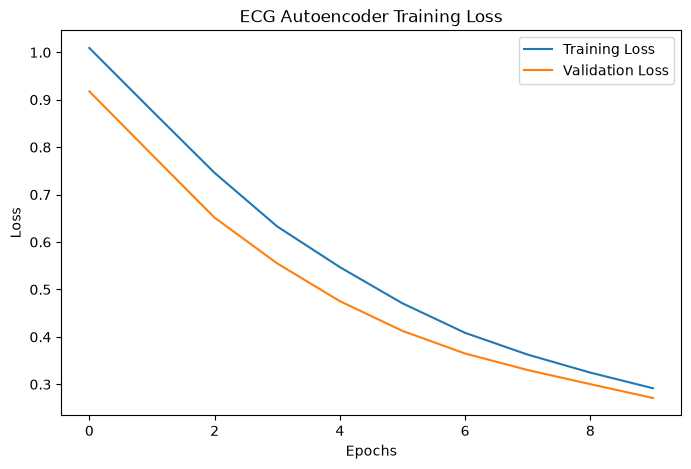

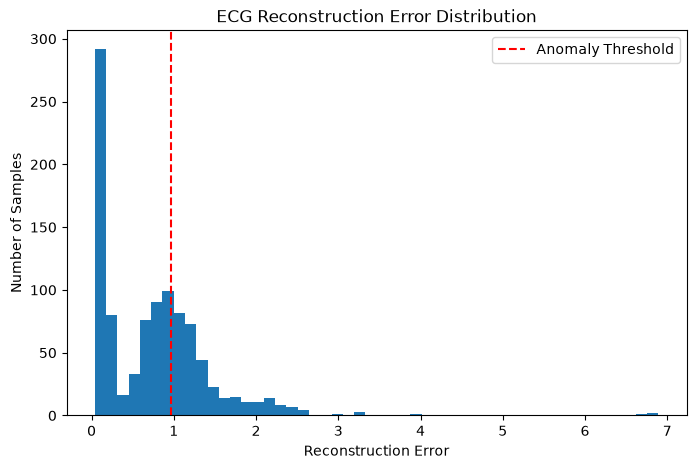

In [1]:

# ECG Anomaly Detection using Autoencoder

# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam


# 2. Load dataset
# header=None because the CSV has no column names
data = pd.read_csv(r'D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\AutoEncoder\ECG\ecg.csv', header=None)

print("Dataset Shape:", data.shape)
print("Label Counts:")
print(data.iloc[:, -1].value_counts())

# Separate features and labels
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values.astype(int)


# 3. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# 4. Keep only normal ECG signals for training
X_train_normal = X_train[y_train == 0]

# Divide normal training data into training and validation
X_train_normal, X_val_normal = train_test_split(
    X_train_normal,
    test_size=0.2,
    random_state=42
)


# 5. Scale the data
scaler = StandardScaler()

X_train_normal = scaler.fit_transform(X_train_normal)
X_val_normal = scaler.transform(X_val_normal)
X_test = scaler.transform(X_test)

print("\nNormal Training Data:", X_train_normal.shape)
print("Validation Data:", X_val_normal.shape)
print("Testing Data:", X_test.shape)


# 6. Build Autoencoder
input_dim = X_train_normal.shape[1]

input_layer = Input(shape=(input_dim,))

# Encoder
encoded = Dense(64, activation='relu')(input_layer)
encoded = Dense(32, activation='relu')(encoded)

# Decoder
decoded = Dense(64, activation='relu')(encoded)
decoded = Dense(input_dim, activation='linear')(decoded)

autoencoder = Model(input_layer, decoded)


# 7. Compile model
autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

autoencoder.summary()


# 8. Train Autoencoder
history = autoencoder.fit(
    X_train_normal,
    X_train_normal,
    epochs=10,
    batch_size=128,
    validation_data=(X_val_normal, X_val_normal),
    shuffle=True
)


# 9. Calculate reconstruction error on normal validation data
val_predictions = autoencoder.predict(X_val_normal)

val_errors = np.mean(
    np.square(X_val_normal - val_predictions),
    axis=1
)

# Set threshold using 95th percentile
threshold = np.percentile(val_errors, 95)

print("\nReconstruction Error Threshold:", threshold)


# 10. Calculate reconstruction error on test data
test_predictions = autoencoder.predict(X_test)

test_errors = np.mean(
    np.square(X_test - test_predictions),
    axis=1
)


# 11. Detect anomalies
y_pred = (test_errors > threshold).astype(int)

print("\nPredicted Anomalies:", np.sum(y_pred))
print("Actual Anomalies:", np.sum(y_test == 1))


# 12. Evaluate model
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


# 13. Plot training and validation loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('ECG Autoencoder Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()


# 14. Plot reconstruction error
plt.figure(figsize=(8, 5))

plt.hist(test_errors, bins=50)
plt.axvline(
    threshold,
    color='red',
    linestyle='--',
    label='Anomaly Threshold'
)

plt.title('ECG Reconstruction Error Distribution')
plt.xlabel('Reconstruction Error')
plt.ylabel('Number of Samples')
plt.legend()
plt.show()


In [2]:
from sklearn.metrics import accuracy_score
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.719


In [3]:
print("Number of anomalies:", np.sum(y_pred))

Number of anomalies: 341


In [4]:
print(threshold)

0.9637606043990194
